In [9]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, _min_token_length

sys.path.append(os.path.expanduser('~/syn-sem'))

from modelpaths import get_model_depths
depths = get_model_depths()
colors, markers, _linestyles = apply_plot_style()

In [10]:
model = 'deepseek'
_model = 'deepseek'

mask = 2
n_files = 500
batch_shuffle = 0
aux_A = 'source'
aux_B = 'target'
k_II = 10
Nbits = 0
seeds = list(range(5))

languageA = 'english'
languageB = 'italian'
n_tokens = 20
avg_tokens = 1

layers = get_layers(_model, depths)
x = layers / depths[_model]

FIGSIZE = (5,4)
LABEL_FONTSIZE = 17
TICK_FONTSIZE = 15
LEGEND_FONTSIZE = 12

# mean_ii, std_ii = load_ii_curves(
#     base='../results/santiago/',
#     batch_shuffle=batch_shuffle,
#     model=model,
#     aux_A=aux_A,
#     aux_B=aux_B,
#     n_files=n_files,
#     min_token_length=_min_token_length(model, languageA, languageB),
#     languageA=languageA,
#     languageB=languageB,
#     mask=mask,
#     k=k_II,
#     Nbits=Nbits,
#     seeds=seeds,
#     n_tokens=n_tokens,
#     avg_tokens=avg_tokens,
# )

# asym_mean = mean_ii[0] - mean_ii[1]
# asym_std = np.sqrt(std_ii[0] ** 2 + std_ii[1] ** 2)
# # label = r'$\mathcal{A}$ = II(English $\rightarrow$ Italian) - II(Italian $\rightarrow$ English)'

# fig, ax = plt.subplots(1, 1, figsize=FIGSIZE)
# ax.plot(
#     x,
#     asym_mean,
#     color=colors[0],
#     marker='o',
#     label=label,
# )

# ax.fill_between(x, asym_mean - asym_std, asym_mean + asym_std, color=colors[0], alpha=0.5)
# ax.axhline(0, color='black', linewidth=1, alpha=0.6)

# ax.set_xlabel('Relative depth', fontsize=LABEL_FONTSIZE)
# ax.set_ylabel('Asymmetry' r'$\mathcal{A}$', fontsize=LABEL_FONTSIZE)
# ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)

# ax.grid()
# ax.legend(loc='lower center', fontsize=LEGEND_FONTSIZE)
# fig.savefig(f'../results/figs/Asymmetry-{languageA}-{languageB}.pdf', bbox_inches='tight')
# plt.show()

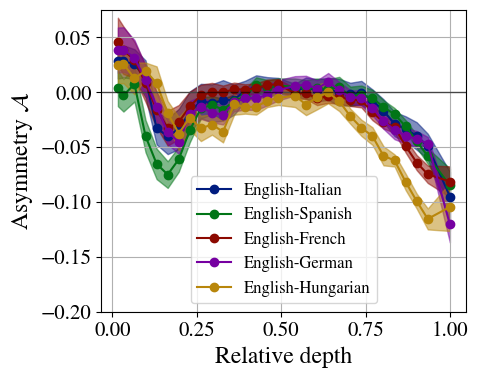

In [11]:
pair_configs = [
    {
        'loadA': 'english',
        'loadB': 'italian',
        'other_display': 'Italian',
        'flip_asymmetry': False,
    },
    {
        'loadA': 'english',
        'loadB': 'spanish',
        'other_display': 'Spanish',
        'flip_asymmetry': False,
    },
    {
        'loadA': 'english',
        'loadB': 'french',
        'other_display': 'French',
        'flip_asymmetry': False,
    },
    {
        # This dataset is stored as German -> English; flip sign to keep EN-DE convention.
        'loadA': 'german',
        'loadB': 'english',
        'other_display': 'German',
        'flip_asymmetry': True,
    },
    {
        'loadA': 'english',
        'loadB': 'hungarian',
        'other_display': 'Hungarian',
        'flip_asymmetry': False,
    },
]

fig, ax = plt.subplots(1, 1, figsize=FIGSIZE)

for i, cfg in enumerate(pair_configs):
    mean_ii, std_ii = load_ii_curves(
        base='../results/santiago/',
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=_min_token_length(model, cfg['loadA'], cfg['loadB']),
        languageA=cfg['loadA'],
        languageB=cfg['loadB'],
        mask=mask,
        k=k_II,
        Nbits=Nbits,
        seeds=seeds,
        n_tokens=n_tokens,
        avg_tokens=avg_tokens,
    )

    asym_mean = mean_ii[0] - mean_ii[1]
    asym_std = np.sqrt(std_ii[0] ** 2 + std_ii[1] ** 2)

    if cfg['flip_asymmetry']:
        asym_mean = -asym_mean

    color = colors[i % len(colors)]
    marker = markers[i % len(markers)]
    label = rf"English-{cfg['other_display']}"

    ax.plot(x, asym_mean, color=color, marker='o', label=label)
    ax.fill_between(x, asym_mean - asym_std, asym_mean + asym_std, color=color, alpha=0.5)

ax.axhline(0, color='black', linewidth=1, alpha=0.6)
ax.set_xlabel('Relative depth', fontsize=LABEL_FONTSIZE)
ax.set_ylabel(r'Asymmetry $\mathcal{A}$', fontsize=LABEL_FONTSIZE)
ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
ax.grid()
ax.legend(loc='lower center', fontsize=LEGEND_FONTSIZE)
ax.set_ylim(-.2,.075)
fig.savefig(f'../results/figs/Asymmetry-EN-multi-{model}.pdf', bbox_inches='tight')
plt.show()



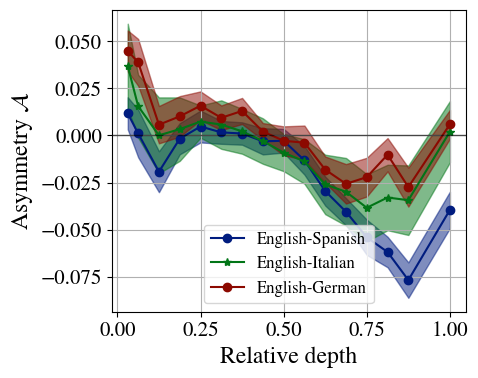

In [12]:
model = 'llama'
_model = 'llama8b'

layers = get_layers(_model, depths)
x = layers / depths[_model]

pair_configs = [
    {
        'loadA': 'english',
        'loadB': 'spanish',
        'other_display': 'Spanish',
        'flip_asymmetry': False,
    },
    {
        'loadA': 'english',
        'loadB': 'italian',
        'other_display': 'Italian',
        'flip_asymmetry': False,
    },
    {
        # Stored as German -> English; flip sign to keep EN-DE asymmetry convention.
        'loadA': 'german',
        'loadB': 'english',
        'other_display': 'German',
        'flip_asymmetry': True,
    },
]

fig, ax = plt.subplots(1, 1, figsize=FIGSIZE)

for i, cfg in enumerate(pair_configs):
    mean_ii, std_ii = load_ii_curves(
        base='../results/santiago/',
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=_min_token_length(model, cfg['loadA'], cfg['loadB']),
        languageA=cfg['loadA'],
        languageB=cfg['loadB'],
        mask=mask,
        k=k_II,
        Nbits=Nbits,
        seeds=seeds,
        n_tokens=n_tokens,
        avg_tokens=avg_tokens,
    )

    asym_mean = mean_ii[0] - mean_ii[1]
    asym_std = np.sqrt(std_ii[0] ** 2 + std_ii[1] ** 2)

    if cfg['flip_asymmetry']:
        asym_mean = -asym_mean

    color = colors[i % len(colors)]
    marker = markers[i % len(markers)]
    label = rf"English-{cfg['other_display']}"

    ax.plot(x, asym_mean, color=color, marker=marker, label=label)
    ax.fill_between(x, asym_mean - asym_std, asym_mean + asym_std, color=color, alpha=0.5)

ax.axhline(0, color='black', linewidth=1, alpha=0.6)
ax.set_xlabel('Relative depth', fontsize=LABEL_FONTSIZE)
ax.set_ylabel(r'Asymmetry $\mathcal{A}$', fontsize=LABEL_FONTSIZE)
ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
ax.grid()
ax.legend(loc='lower center', fontsize=LEGEND_FONTSIZE)
fig.savefig(f'../results/figs/Asymmetry-EN-multi-{model}.pdf', bbox_inches='tight')
plt.show()
